In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


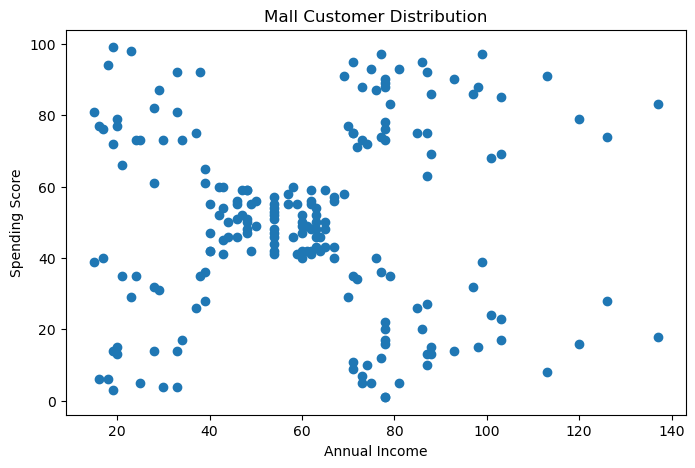

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Mall Customer Distribution')

plt.show()

In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

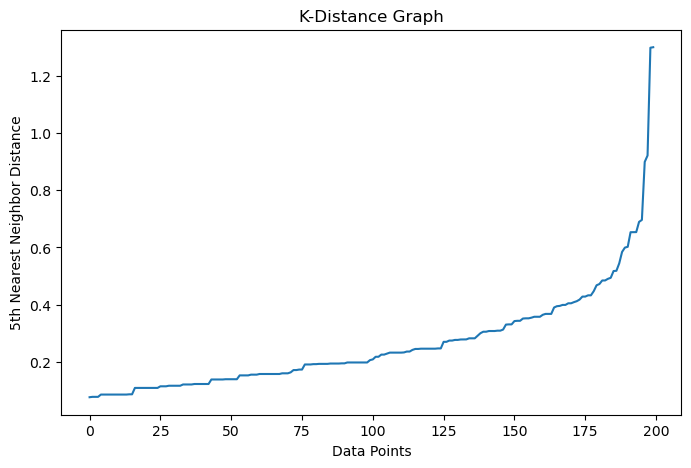

In [11]:
neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 5))

plt.plot(distances)

plt.xlabel('Data Points')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('K-Distance Graph')

plt.show()

In [12]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

df['Cluster'] = labels

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [13]:
print("Cluster Labels:", np.unique(labels))

print("Number of Clusters:", len(set(labels)) - (1 if -1 in labels else 0))

print("Number of Noise Points:", list(labels).count(-1))

Cluster Labels: [-1  0  1]
Number of Clusters: 2
Number of Noise Points: 8


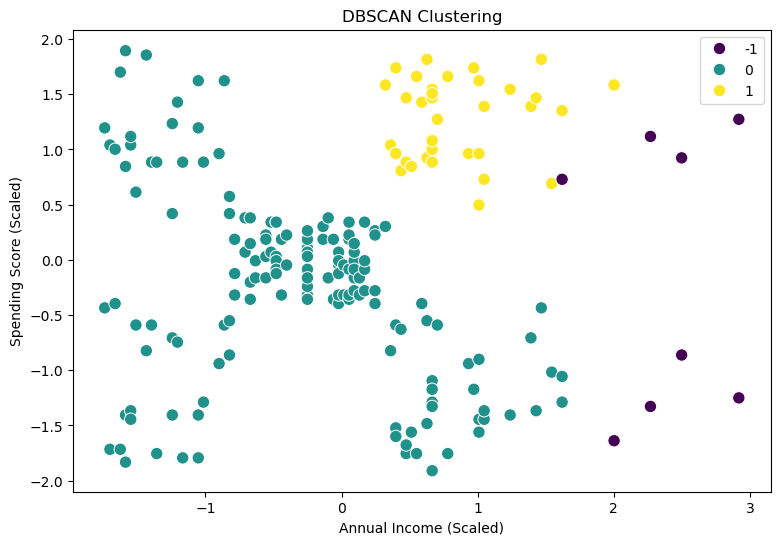

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=labels,
    palette='viridis',
    s=80
)

plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.title('DBSCAN Clustering')

plt.show()

In [15]:
core_samples = dbscan.core_sample_indices_

core_points = np.zeros(len(labels), dtype=bool)
core_points[core_samples] = True

border_points = (labels != -1) & (~core_points)
noise_points = labels == -1

print("Core Points:", core_points.sum())
print("Border Points:", border_points.sum())
print("Noise Points:", noise_points.sum())

Core Points: 185
Border Points: 7
Noise Points: 8


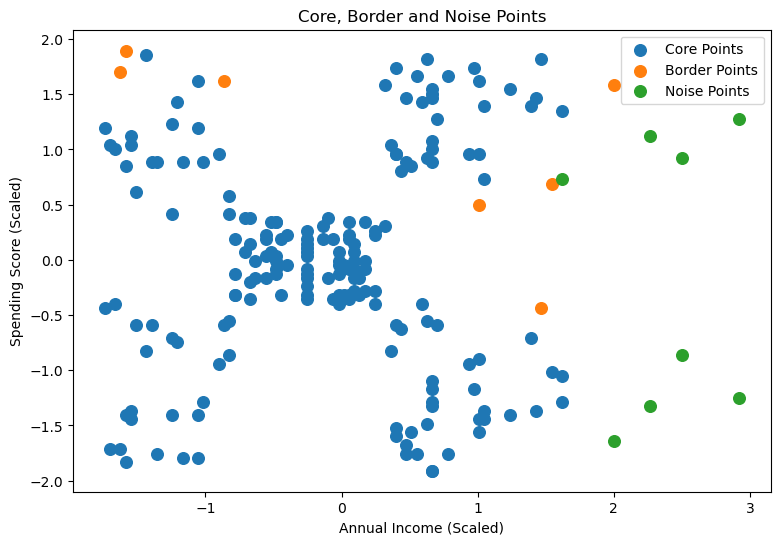

In [16]:
plt.figure(figsize=(9, 6))

plt.scatter(X_scaled[core_points, 0], X_scaled[core_points, 1],
            label='Core Points', s=70)

plt.scatter(X_scaled[border_points, 0], X_scaled[border_points, 1],
            label='Border Points', s=70)

plt.scatter(X_scaled[noise_points, 0], X_scaled[noise_points, 1],
            label='Noise Points', s=70)

plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.title('Core, Border and Noise Points')

plt.legend()
plt.show()

In [17]:
print(df['Cluster'].value_counts().sort_index())

Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64


In [18]:
df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
Cluster,,
-1,122.750000,46.875000
0,52.490446,43.101911
1,82.542857,82.800000


In [19]:
df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
Cluster,,
-1,122.750000,46.875000
0,52.490446,43.101911
1,82.542857,82.800000


In [20]:
if len(set(labels)) > 1 and len(set(labels)) < len(labels):
    print("Silhouette Score:", silhouette_score(X_scaled, labels))
else:
    print("Silhouette Score cannot be calculated.")

Silhouette Score: 0.35044619989666004


In [21]:
print("DBSCAN Clustering Completed Successfully")
print("Total Customers:", len(df))
print("Total Clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Total Noise Points:", list(labels).count(-1))

DBSCAN Clustering Completed Successfully
Total Customers: 200
Total Clusters: 2
Total Noise Points: 8


In [22]:
print("Cluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

print("\nCore Points:", core_points.sum())
print("Border Points:", border_points.sum())
print("Noise Points:", noise_points.sum())

Cluster Distribution:
Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64

Core Points: 185
Border Points: 7
Noise Points: 8
